# Statistical testing

Significance tests over the benchmark grid. Unit of analysis is the subject: seeds are
averaged first, so all tests are paired over the same 9 subjects. Friedman omnibus,
Wilcoxon signed-rank post-hoc, Holm correction within each family, BCa bootstrap intervals.

Reference: Demsar (2006), JMLR 7, 1-30; Holm (1979), Scand. J. Statist. 6, 65-70.

In [27]:
import json
from pathlib import Path
from typing import Any, cast

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import binomtest, bootstrap, friedmanchisquare, rankdata, wilcoxon

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
GRIDS = ["runs/grid-iv2a", "runs/grid-iv2a-22ch", "runs/grid-iv2b"]
OUT = ROOT / "runs" / "statistics"
METRIC = "accuracy"
ALPHA = 0.05
SEED = 0
CHANCE = {"bci_iv_2a": 0.25, "bci_iv_2b": 0.5}
FACTORS = ["dataset", "montage", "preprocessing", "model"]

OUT.mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 200)
pd.set_option("display.max_rows", 100)

## 1. Load runs

In [28]:
def load_runs() -> pd.DataFrame:
    """One row per completed run: factors, channels used, trial count and metrics."""
    rows = []
    for grid in GRIDS:
        for cell in sorted(p for p in (ROOT / grid).iterdir() if p.is_dir()):
            montage = cell.name.rsplit("_seed", 1)[0].rsplit("_", 1)[-1]
            for run in sorted(p for p in cell.iterdir() if p.is_dir()):
                if not (run / ".run_complete").exists():
                    continue
                result = json.loads((run / "result.json").read_text())
                manifest = json.loads((run / "manifest.json").read_text())
                rows.append(
                    {
                        "dataset": result["dataset"],
                        "montage": montage,
                        "preprocessing": result["preprocessing"],
                        "model": result["model"],
                        "seed": result["seed"],
                        "subject": run.name,
                        "n_test": result["n_trials"]["test"],
                        "n_channels": len(manifest["channels_used"]),
                        **result["metrics"],
                    }
                )
    return pd.DataFrame(rows)


runs = load_runs()
print(len(runs), "runs")
print(runs.groupby(["dataset", "montage"])["n_channels"].first())

1620 runs
dataset    montage
bci_iv_2a  all        22
           galea       4
bci_iv_2b  galea       3
Name: n_channels, dtype: int64


## 2. Tests

In [29]:
def groups(df: pd.DataFrame, by: list[str]) -> list[tuple[tuple, pd.DataFrame]]:
    """(key, sub-frame) pairs of a groupby, with the key typed as a tuple."""
    return cast(list[tuple[tuple, pd.DataFrame]], list(df.groupby(by)))


def metric_of(grouped) -> Any:
    """The metric column of a groupby; selecting a column by variable widens its type."""
    return cast(Any, grouped[METRIC])


def matrix(df: pd.DataFrame, by: str) -> pd.DataFrame:
    """Seed-averaged metric as a (condition, subject) table; conditions are levels of by."""
    return df.pivot_table(index=by, columns="subject", values=METRIC, aggfunc="mean")


def holm(p_values) -> list[float]:
    """Holm-Bonferroni adjusted p-values."""
    p = np.asarray(p_values, dtype=float)
    order = np.argsort(p)
    scaled = np.maximum.accumulate(p[order] * (p.size - np.arange(p.size)))
    adjusted = np.empty(p.size)
    adjusted[order] = np.minimum(scaled, 1.0)
    return list(adjusted)


def friedman(table: pd.DataFrame) -> dict:
    """Friedman omnibus over the rows of table, blocked by subject, with Kendall's W."""
    k, n = table.shape
    chi2, p = cast(tuple[float, float], friedmanchisquare(*table.to_numpy()))
    return {"chi2": chi2, "kendall_w": chi2 / (n * (k - 1)), "p": p}


def signed_rank(a, b, alternative: str = "two-sided") -> dict:
    """Wilcoxon signed-rank test with the rank-biserial correlation as effect size."""
    d = np.asarray(a, dtype=float) - np.asarray(b, dtype=float)
    if not np.any(d):
        return {"w": 0.0, "p": 1.0, "rank_biserial": 0.0, "median_diff": 0.0}
    w, p = cast(tuple[float, float], wilcoxon(a, b, alternative=alternative))
    ranks = rankdata(np.abs(d[d != 0]))
    pos, neg = ranks[d[d != 0] > 0].sum(), ranks[d[d != 0] < 0].sum()
    return {"w": w, "p": p, "rank_biserial": (pos - neg) / (pos + neg),
            "median_diff": float(np.median(d))}


def ci(values) -> tuple[float, float]:
    """BCa bootstrap 95% interval for the mean."""
    result = bootstrap((np.asarray(values, dtype=float),), np.mean, method="BCa",
                       n_resamples=10000, rng=np.random.default_rng(SEED))
    return float(result.confidence_interval.low), float(result.confidence_interval.high)


def pairs(table: pd.DataFrame) -> list[dict]:
    """Every pairwise signed-rank test between the rows of table."""
    names = list(table.index)
    return [
        {"a": names[i], "b": names[j],
         "mean_a": table.iloc[i].mean(), "mean_b": table.iloc[j].mean(),
         **signed_rank(table.iloc[i], table.iloc[j])}
        for i in range(len(names)) for j in range(i + 1, len(names))
    ]


def add_holm(df: pd.DataFrame) -> pd.DataFrame:
    """Holm-correct the p column of df, treating its rows as one family."""
    df = df.copy()
    df["p_holm"] = holm(df["p"])
    df["sig"] = df["p_holm"] < ALPHA
    return df

## 3. Above chance

Exact binomial test on the pooled test trials (one family over all conditions), plus the
subject-level signed-rank test. At n = 9 the signed-rank p cannot go below 0.00195, so the
binomial test carries the resolution and the signed-rank test respects the clustering.

In [30]:
rows = []
for key, group in groups(runs, FACTORS):
    chance = CHANCE[key[0]]
    subjects = metric_of(group.groupby("subject")).mean().to_numpy()
    correct = int(np.round(group[METRIC].to_numpy() * group["n_test"].to_numpy()).sum())
    total = int(group["n_test"].to_numpy().sum())
    low, high = ci(subjects)
    rows.append({
        **dict(zip(FACTORS, key)),
        "mean": float(subjects.mean()), "ci_low": low, "ci_high": high, "chance": chance,
        "p": binomtest(correct, total, chance, alternative="greater").pvalue,
        "p_signed_rank": signed_rank(subjects, np.full(subjects.size, chance), "greater")["p"],
    })

chance_table = add_holm(pd.DataFrame(rows)).sort_values("mean", ascending=False)
print(chance_table["sig"].sum(), "of", len(chance_table), "conditions above chance")
chance_table.round(4)

36 of 36 conditions above chance


,dataset,montage,preprocessing,model,mean,ci_low,ci_high,chance,p,p_signed_rank,p_holm,sig
31,bci_iv_2b,galea,minimal,eegnet,0.8455,0.7856,0.8997,0.50,0.0,0.0020,0.0,True
34,bci_iv_2b,galea,standard,eegnet,0.8287,0.7188,0.8976,0.50,0.0,0.0020,0.0,True
30,bci_iv_2b,galea,minimal,eeg_conformer,0.8158,0.7520,0.8743,0.50,0.0,0.0020,0.0,True
33,bci_iv_2b,galea,standard,eeg_conformer,0.7958,0.6750,0.8737,0.50,0.0,0.0020,0.0,True
35,bci_iv_2b,galea,standard,grf_net,0.7810,0.6625,0.8588,0.50,0.0,0.0020,0.0,True
32,bci_iv_2b,galea,minimal,grf_net,0.7690,0.6784,0.8231,0.50,0.0,0.0020,0.0,True
24,bci_iv_2b,galea,deep,eeg_conformer,0.7408,0.6181,0.8349,0.50,0.0,0.0039,0.0,True
27,bci_iv_2b,galea,maximum,eeg_conformer,0.7359,0.6170,0.8302,0.50,0.0,0.0020,0.0,True
1,bci_iv_2a,all,deep,eegnet,0.7249,0.6341,0.8083,0.25,0.0,0.0020,0.0,True
25,bci_iv_2b,galea,deep,eegnet,0.7222,0.6064,0.8141,0.50,0.0,0.0020,0.0,True


## 4. Models

In [31]:
omnibus, posthoc = [], []
for key, group in groups(runs, ["dataset", "montage", "preprocessing"]):
    table = matrix(group, "model")
    omnibus.append({**dict(zip(["dataset", "montage", "preprocessing"], key)),
                    **table.mean(axis=1).round(4).to_dict(), **friedman(table)})
    for pair in add_holm(pd.DataFrame(pairs(table))).to_dict("records"):
        posthoc.append({**dict(zip(["dataset", "montage", "preprocessing"], key)), **pair})

model_omnibus = pd.DataFrame(omnibus)
model_posthoc = pd.DataFrame(posthoc)
model_omnibus.round(4)

,dataset,montage,preprocessing,eeg_conformer,eegnet,grf_net,chi2,kendall_w,p
0,bci_iv_2a,all,deep,0.7026,0.7249,0.7059,2.8889,0.1605,0.2359
1,bci_iv_2a,all,maximum,0.6654,0.7064,0.6986,1.2000,0.0667,0.5488
2,bci_iv_2a,all,minimal,0.6549,0.6848,0.6348,0.8889,0.0494,0.6412
3,bci_iv_2a,all,standard,0.6113,0.6788,0.6387,4.2222,0.2346,0.1211
4,bci_iv_2a,galea,deep,0.5936,0.5990,0.5735,6.2222,0.3457,0.0446
5,bci_iv_2a,galea,maximum,0.5893,0.6009,0.5705,6.2222,0.3457,0.0446
6,bci_iv_2a,galea,minimal,0.5578,0.6271,0.5617,10.8889,0.6049,0.0043
7,bci_iv_2a,galea,standard,0.5225,0.5692,0.5575,8.2222,0.4568,0.0164
8,bci_iv_2b,galea,deep,0.7408,0.7222,0.6839,8.2222,0.4568,0.0164
9,bci_iv_2b,galea,maximum,0.7359,0.7204,0.6850,6.2286,0.3460,0.0444


In [32]:
print(model_posthoc["sig"].sum(), "of", len(model_posthoc), "model pairs significant")
model_posthoc[model_posthoc["sig"]].round(4)

8 of 36 model pairs significant


,dataset,montage,preprocessing,a,b,mean_a,mean_b,w,p,rank_biserial,median_diff,p_holm,sig
18,bci_iv_2a,galea,minimal,eeg_conformer,eegnet,0.5578,0.6271,0.0,0.0039,-1.0000,-0.0563,0.0117,True
21,bci_iv_2a,galea,standard,eeg_conformer,eegnet,0.5225,0.5692,0.0,0.0039,-1.0000,-0.0514,0.0117,True
25,bci_iv_2b,galea,deep,eeg_conformer,grf_net,0.7408,0.6839,3.0,0.0195,0.8667,0.0469,0.0391,True
26,bci_iv_2b,galea,deep,eegnet,grf_net,0.7222,0.6839,0.0,0.0039,1.0000,0.0262,0.0117,True
28,bci_iv_2b,galea,maximum,eeg_conformer,grf_net,0.7359,0.6850,3.0,0.0195,0.8667,0.0363,0.0391,True
29,bci_iv_2b,galea,maximum,eegnet,grf_net,0.7204,0.6850,1.0,0.0078,0.9556,0.0263,0.0234,True
30,bci_iv_2b,galea,minimal,eeg_conformer,eegnet,0.8158,0.8455,0.0,0.0039,-1.0000,-0.0286,0.0117,True
35,bci_iv_2b,galea,standard,eegnet,grf_net,0.8287,0.7810,0.0,0.0039,1.0000,0.0431,0.0117,True


## 5. Preprocessing

In [33]:
omnibus, posthoc = [], []
for key, group in groups(runs, ["dataset", "montage", "model"]):
    table = matrix(group, "preprocessing")
    omnibus.append({**dict(zip(["dataset", "montage", "model"], key)),
                    **table.mean(axis=1).round(4).to_dict(), **friedman(table)})
    for pair in add_holm(pd.DataFrame(pairs(table))).to_dict("records"):
        posthoc.append({**dict(zip(["dataset", "montage", "model"], key)), **pair})

prep_omnibus = pd.DataFrame(omnibus)
prep_posthoc = pd.DataFrame(posthoc)
prep_omnibus.round(4)

,dataset,montage,model,deep,maximum,minimal,standard,chi2,kendall_w,p
0,bci_iv_2a,all,eeg_conformer,0.7026,0.6654,0.6549,0.6113,9.6667,0.3580,0.0216
1,bci_iv_2a,all,eegnet,0.7249,0.7064,0.6848,0.6788,5.1333,0.1901,0.1623
2,bci_iv_2a,all,grf_net,0.7059,0.6986,0.6348,0.6387,15.6667,0.5802,0.0013
3,bci_iv_2a,galea,eeg_conformer,0.5936,0.5893,0.5578,0.5225,9.8000,0.3630,0.0203
4,bci_iv_2a,galea,eegnet,0.5990,0.6009,0.6271,0.5692,2.8667,0.1062,0.4126
5,bci_iv_2a,galea,grf_net,0.5735,0.5705,0.5617,0.5575,2.7333,0.1012,0.4346
6,bci_iv_2b,galea,eeg_conformer,0.7408,0.7359,0.8158,0.7958,7.5333,0.2790,0.0567
7,bci_iv_2b,galea,eegnet,0.7222,0.7204,0.8455,0.8287,15.6667,0.5802,0.0013
8,bci_iv_2b,galea,grf_net,0.6839,0.6850,0.7690,0.7810,11.5227,0.4268,0.0092


In [34]:
print(prep_posthoc["sig"].sum(), "of", len(prep_posthoc), "preprocessing pairs significant")
prep_posthoc[prep_posthoc["sig"]].round(4)

7 of 54 preprocessing pairs significant


,dataset,montage,model,a,b,mean_a,mean_b,w,p,rank_biserial,median_diff,p_holm,sig
13,bci_iv_2a,all,grf_net,deep,minimal,0.7059,0.6348,1.0,0.0078,0.9556,0.0215,0.0391,True
14,bci_iv_2a,all,grf_net,deep,standard,0.7059,0.6387,0.0,0.0039,1.0000,0.0451,0.0234,True
20,bci_iv_2a,galea,eeg_conformer,deep,standard,0.5936,0.5225,1.0,0.0078,0.9556,0.0701,0.0469,True
43,bci_iv_2b,galea,eegnet,deep,minimal,0.7222,0.8455,1.0,0.0078,-0.9556,-0.0925,0.0391,True
44,bci_iv_2b,galea,eegnet,deep,standard,0.7222,0.8287,1.0,0.0078,-0.9556,-0.1194,0.0391,True
45,bci_iv_2b,galea,eegnet,maximum,minimal,0.7204,0.8455,0.0,0.0039,-1.0000,-0.0856,0.0234,True
46,bci_iv_2b,galea,eegnet,maximum,standard,0.7204,0.8287,2.0,0.0117,-0.9111,-0.1100,0.0391,True


## 6. Montage

Full montage against the Galea subset, paired per (model, preprocessing), one family for
the dataset. Only 2a has both, where the subset is the 4 electrodes it shares with the
Galea headset, so this is 22 channels against 4.

In [35]:
rows = []
iv2a = cast(pd.DataFrame, runs[runs["dataset"] == "bci_iv_2a"])
for key, group in groups(iv2a, ["model", "preprocessing"]):
    table = matrix(group, "montage")
    loss = table.loc["all"] - table.loc["galea"]
    low, high = ci(loss)
    rows.append({"model": key[0], "preprocessing": key[1],
                 "mean_all": table.loc["all"].mean(), "mean_galea": table.loc["galea"].mean(),
                 "mean_loss": loss.mean(), "ci_low": low, "ci_high": high,
                 **signed_rank(table.loc["all"], table.loc["galea"])})

montage_table = add_holm(pd.DataFrame(rows))
print(montage_table["sig"].sum(), "of", len(montage_table), "montage tests significant;",
      f"mean loss {montage_table['mean_loss'].mean():.4f}")
montage_table.round(4)

9 of 12 montage tests significant; mean loss 0.0987


,model,preprocessing,mean_all,mean_galea,mean_loss,ci_low,ci_high,w,p,rank_biserial,median_diff,p_holm,sig
0,eeg_conformer,deep,0.7026,0.5936,0.1090,0.0617,0.1572,0.0,0.0039,1.0000,0.1208,0.0469,True
1,eeg_conformer,maximum,0.6654,0.5893,0.0762,0.0208,0.1499,5.0,0.0391,0.7778,0.0326,0.0820,False
2,eeg_conformer,minimal,0.6549,0.5578,0.0971,0.0627,0.1381,0.0,0.0039,1.0000,0.0840,0.0469,True
3,eeg_conformer,standard,0.6113,0.5225,0.0888,0.0256,0.1801,7.0,0.0742,0.6889,0.0549,0.0820,False
4,eegnet,deep,0.7249,0.5990,0.1259,0.0721,0.1602,0.0,0.0039,1.0000,0.1486,0.0469,True
5,eegnet,maximum,0.7064,0.6009,0.1055,0.0551,0.1482,2.0,0.0117,0.9111,0.1035,0.0469,True
6,eegnet,minimal,0.6848,0.6271,0.0577,0.0190,0.0754,1.0,0.0078,0.9556,0.0632,0.0469,True
7,eegnet,standard,0.6788,0.5692,0.1096,0.0848,0.1426,0.0,0.0039,1.0000,0.1007,0.0469,True
8,grf_net,deep,0.7059,0.5735,0.1323,0.0956,0.1738,0.0,0.0039,1.0000,0.1222,0.0469,True
9,grf_net,maximum,0.6986,0.5705,0.1281,0.0916,0.1838,0.0,0.0039,1.0000,0.1194,0.0469,True


## 7. Seed stability

Within-subject spread over seeds. If it is larger than the differences the tests resolve,
those differences are training noise.

In [36]:
per_subject = metric_of(runs.groupby(FACTORS + ["subject"])).std().reset_index()
seed_table = metric_of(per_subject.groupby(FACTORS)).mean().reset_index()
seed_table.columns = FACTORS + ["seed_sd"]
seed_table = seed_table.sort_values("seed_sd", ascending=False)
print(f"median seed sd {seed_table['seed_sd'].median():.4f}, "
      f"median model difference {model_posthoc['median_diff'].abs().median():.4f}")
seed_table.head(10).round(4)

median seed sd 0.0326, median model difference 0.0263


,dataset,montage,preprocessing,model,seed_sd
3,bci_iv_2a,all,maximum,eeg_conformer,0.0639
9,bci_iv_2a,all,standard,eeg_conformer,0.0633
6,bci_iv_2a,all,minimal,eeg_conformer,0.0525
18,bci_iv_2a,galea,minimal,eeg_conformer,0.0513
8,bci_iv_2a,all,minimal,grf_net,0.0483
0,bci_iv_2a,all,deep,eeg_conformer,0.0465
21,bci_iv_2a,galea,standard,eeg_conformer,0.0458
30,bci_iv_2b,galea,minimal,eeg_conformer,0.0437
11,bci_iv_2a,all,standard,grf_net,0.0427
12,bci_iv_2a,galea,deep,eeg_conformer,0.0409


## 8. Save

In [37]:
tables = {"chance": chance_table, "models_omnibus": model_omnibus,
          "models_posthoc": model_posthoc, "preprocessing_omnibus": prep_omnibus,
          "preprocessing_posthoc": prep_posthoc, "montage": montage_table,
          "seed_stability": seed_table}
for name, table in tables.items():
    table.to_csv(OUT / f"{METRIC}_{name}.csv", index=False)
    print(f"{len(table):3d} rows -> runs/statistics/{METRIC}_{name}.csv")

 36 rows -> runs/statistics/accuracy_chance.csv
 12 rows -> runs/statistics/accuracy_models_omnibus.csv
 36 rows -> runs/statistics/accuracy_models_posthoc.csv
  9 rows -> runs/statistics/accuracy_preprocessing_omnibus.csv
 54 rows -> runs/statistics/accuracy_preprocessing_posthoc.csv
 12 rows -> runs/statistics/accuracy_montage.csv
 36 rows -> runs/statistics/accuracy_seed_stability.csv


## 9. Figures

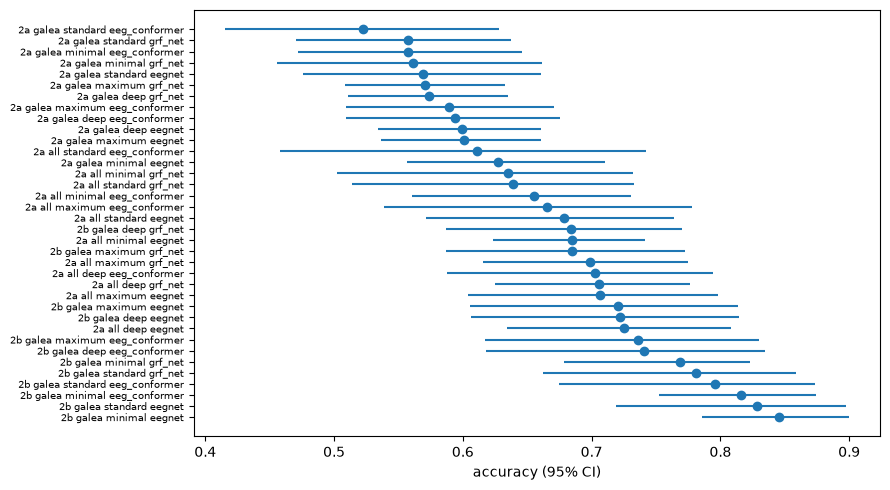

In [38]:
fig, ax = plt.subplots(figsize=(9, 5))
labels = chance_table["dataset"].str.replace("bci_iv_", "") + " " + chance_table["montage"] \
    + " " + chance_table["preprocessing"] + " " + chance_table["model"]
y = np.arange(len(chance_table))
ax.errorbar(chance_table["mean"], y, fmt="o",
            xerr=[chance_table["mean"] - chance_table["ci_low"],
                  chance_table["ci_high"] - chance_table["mean"]])
ax.set_yticks(y)
ax.set_yticklabels(labels, fontsize=7)
ax.set_xlabel(f"{METRIC} (95% CI)")
fig.tight_layout()
fig.savefig(OUT / f"{METRIC}_conditions.png", dpi=150)

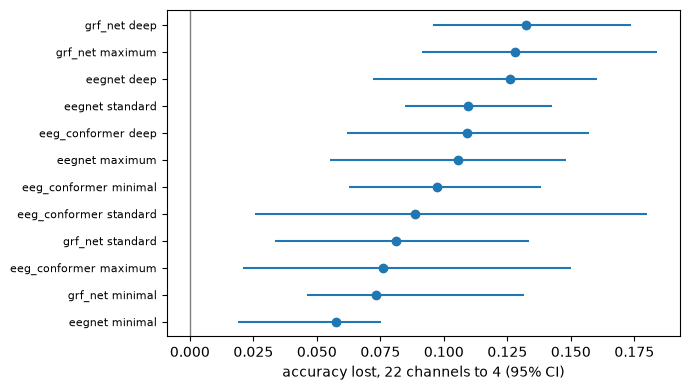

In [39]:
fig, ax = plt.subplots(figsize=(7, 4))
ordered = montage_table.sort_values("mean_loss")
y = np.arange(len(ordered))
ax.errorbar(ordered["mean_loss"], y, fmt="o",
            xerr=[ordered["mean_loss"] - ordered["ci_low"],
                  ordered["ci_high"] - ordered["mean_loss"]])
ax.axvline(0, color="grey", linewidth=1)
ax.set_yticks(y)
ax.set_yticklabels(ordered["model"] + " " + ordered["preprocessing"], fontsize=8)
ax.set_xlabel(f"{METRIC} lost, 22 channels to 4 (95% CI)")
fig.tight_layout()
fig.savefig(OUT / f"{METRIC}_montage.png", dpi=150)